# Prueba con resultados de DIC y DOC

In [1]:
import pandas as pd
import plotly.express as px
from IPython.display import display
import matplotlib.pyplot as plt
#import seaborn as sns


In [2]:
# Carga del archivo CSV de asadas en un DataFrame
datos = pd.read_csv("D:\Documentos\Python\TropDOC\FinalDataset_Prueba.csv", sep=";", encoding="cp1252")

# Primeras filas
datos.head()

<>:2: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:2: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\Torneca\AppData\Local\Temp\ipykernel_35848\863738638.py:2: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  datos = pd.read_csv("D:\Documentos\Python\TropDOC\FinalDataset_Prueba.csv", sep=";", encoding="cp1252")


,ï»¿Site,sample_type,sampling_point,Notes,sample_set,sampling_date,labwork_date,pH,EC,DIC,DOC,Comments
0,La Hilda,Streamwater,Point 1,Creek by the church from reservoir,1,07.05.2025,13.05.2025,7.8,158.2,5.11078194,12.35,NaN
1,La Hilda,Streamwater,Point 2,Creek with secondary forest cover,1,07.05.2025,07.05.2025,-,-,-,-,"Did not get water due to accessbility, the poi..."
2,La Hilda,Streamwater,Point 3,Forest in the farm,1,07.05.2025,09.05.2025,8,210,5.45558315,14.22,NaN
3,La Hilda,Streamwater,Point 4,Bridge in the farm,1,07.05.2025,13.05.2025,7.9,197.5,0.015500638,14.05,Sensor
4,La Hilda,Streamwater,Point 5,Leave the fram,1,07.05.2025,13.05.2025,7.6,105.8,3.055102029,8.33,NaN


In [3]:
datos.dtypes



ï»¿Site             str
sample_type         str
sampling_point      str
Notes               str
sample_set        int64
sampling_date       str
labwork_date        str
pH                  str
EC                  str
DIC                 str
DOC                 str
Comments            str
dtype: object

In [4]:
for col in ["sampling_date", "labwork_date"]:
    datos[col] = pd.to_datetime(datos[col], format='%d.%m.%Y', errors='coerce')

datos["DIC"] = pd.to_numeric(datos["DIC"], errors='coerce')

datos["DOC"] = pd.to_numeric(datos["DOC"], errors='coerce')

datos

#df['mi_fecha'] = pd.to_datetime(df['mi_fecha'], format='%d.%m.%Y')

,ï»¿Site,sample_type,sampling_point,Notes,sample_set,sampling_date,labwork_date,pH,EC,DIC,DOC,Comments
0,La Hilda,Streamwater,Point 1,Creek by the church from reservoir,1,2025-05-07,2025-05-13,7.8,158.2,5.110782,12.35,NaN
1,La Hilda,Streamwater,Point 2,Creek with secondary forest cover,1,2025-05-07,2025-05-07,-,-,NaN,NaN,"Did not get water due to accessbility, the poi..."
2,La Hilda,Streamwater,Point 3,Forest in the farm,1,2025-05-07,2025-05-09,8,210,5.455583,14.22,NaN
3,La Hilda,Streamwater,Point 4,Bridge in the farm,1,2025-05-07,2025-05-13,7.9,197.5,0.015501,14.05,Sensor
4,La Hilda,Streamwater,Point 5,Leave the fram,1,2025-05-07,2025-05-13,7.6,105.8,3.055102,8.33,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
112,La Hilda,Streamwater,Point 3,Forest in the farm,19,2026-10-29,2026-10-29,7.9,190,3.718264,NaN,NaN
113,La Hilda,Streamwater,Point 4,Bridge in the farm,19,2026-10-29,2026-10-29,8,190,4.680404,NaN,NaN
114,La Hilda,Streamwater,Point 5,Leave the farm,19,2026-10-29,2026-10-29,7.9,170,4.476492,NaN,NaN
115,La Hilda,Streamwater,Point 6,Creek near seasonal spring,19,2026-10-29,2026-10-29,8,170,4.679668,NaN,NaN


In [5]:
# 2. Drop rows where date or your target variable (e.g., 'EC') is missing
datos_clean = datos.dropna(subset=["sampling_point", "sampling_date", "DIC"]).sort_values("sampling_date")

# 3. Sort by date chronologically (essential for line plots)
#datos_clean = datos_clean.sort_values("sampling_date")

datos_clean

,ï»¿Site,sample_type,sampling_point,Notes,sample_set,sampling_date,labwork_date,pH,EC,DIC,DOC,Comments
0,La Hilda,Streamwater,Point 1,Creek by the church from reservoir,1,2025-05-07,2025-05-13,7.8,158.2,5.110782,12.35,NaN
2,La Hilda,Streamwater,Point 3,Forest in the farm,1,2025-05-07,2025-05-09,8,210,5.455583,14.22,NaN
3,La Hilda,Streamwater,Point 4,Bridge in the farm,1,2025-05-07,2025-05-13,7.9,197.5,0.015501,14.05,Sensor
4,La Hilda,Streamwater,Point 5,Leave the fram,1,2025-05-07,2025-05-13,7.6,105.8,3.055102,8.33,NaN
5,La Hilda,Streamwater,Point 1,Creek by the church from reservoir,2,2025-06-04,2025-06-05,7.7,109.1,2.921012,2.16,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
111,La Hilda,Streamwater,Point 2,Creek with secondary forest cover,19,2026-10-29,2026-10-29,7.5,160,2.371856,NaN,NaN
112,La Hilda,Streamwater,Point 3,Forest in the farm,19,2026-10-29,2026-10-29,7.9,190,3.718264,NaN,NaN
113,La Hilda,Streamwater,Point 4,Bridge in the farm,19,2026-10-29,2026-10-29,8,190,4.680404,NaN,NaN
114,La Hilda,Streamwater,Point 5,Leave the farm,19,2026-10-29,2026-10-29,7.9,170,4.476492,NaN,NaN


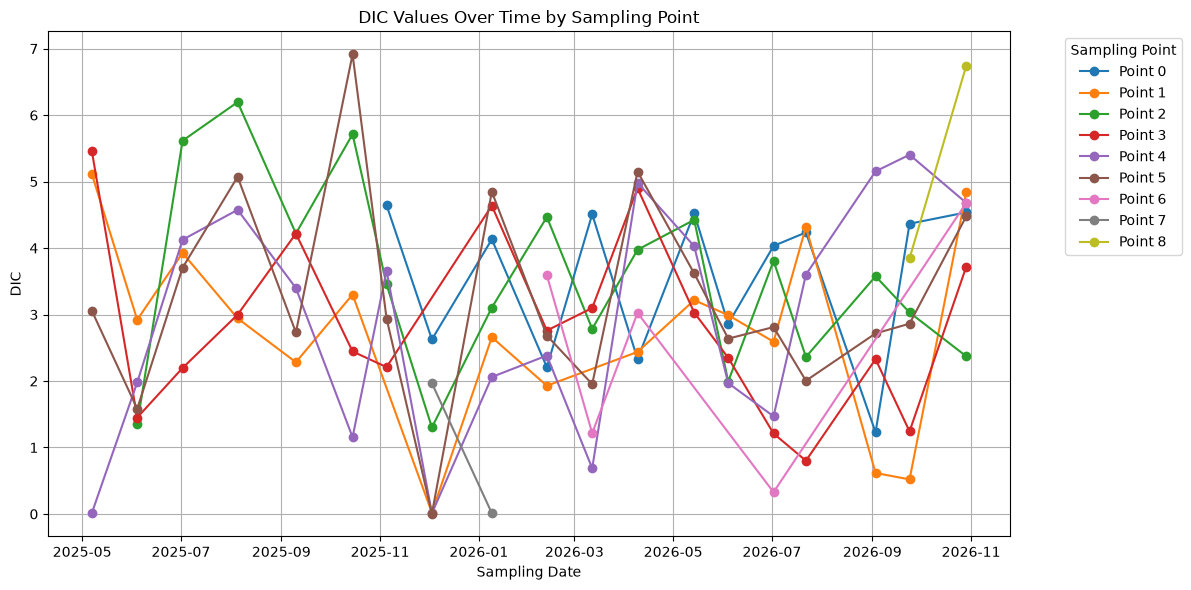

In [6]:
# 3. Create the plot
fig, ax = plt.subplots(figsize=(12, 6))

# Loop through each unique sampling point and plot its data
for point, group in datos_clean.groupby("sampling_point"):
    ax.plot(group["sampling_date"], group["DIC"], marker="o", label=point)

# Add formatting, labels, and legend
ax.set_xlabel("Sampling Date")
ax.set_ylabel("DIC")
ax.set_title("DIC Values Over Time by Sampling Point")
ax.legend(title="Sampling Point", bbox_to_anchor=(1.05, 1), loc='upper left') # Puts legend outside the plot
ax.grid(True)

plt.tight_layout()
plt.show()

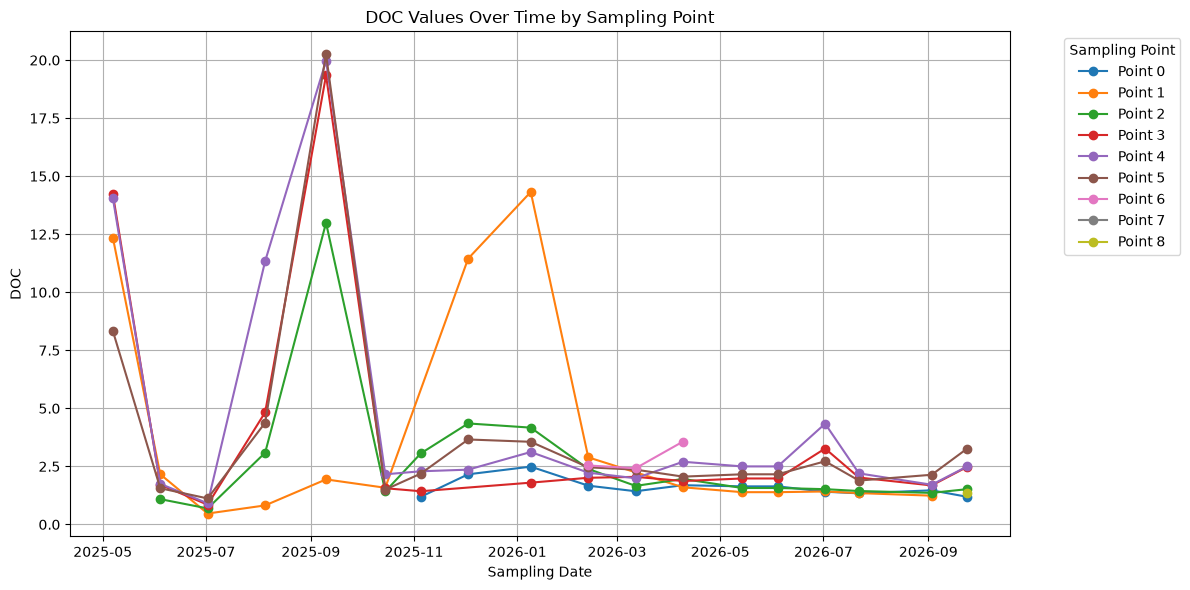

In [7]:
# 3. Create the plot
fig, ax = plt.subplots(figsize=(12, 6))

# Loop through each unique sampling point and plot its data
for point, group in datos_clean.groupby("sampling_point"):
    ax.plot(group["sampling_date"], group["DOC"], marker="o", label=point)

# Add formatting, labels, and legend
ax.set_xlabel("Sampling Date")
ax.set_ylabel("DOC")
ax.set_title("DOC Values Over Time by Sampling Point")
ax.legend(title="Sampling Point", bbox_to_anchor=(1.05, 1), loc='upper left') # Puts legend outside the plot
ax.grid(True)

plt.tight_layout()
plt.show()

## for 2026

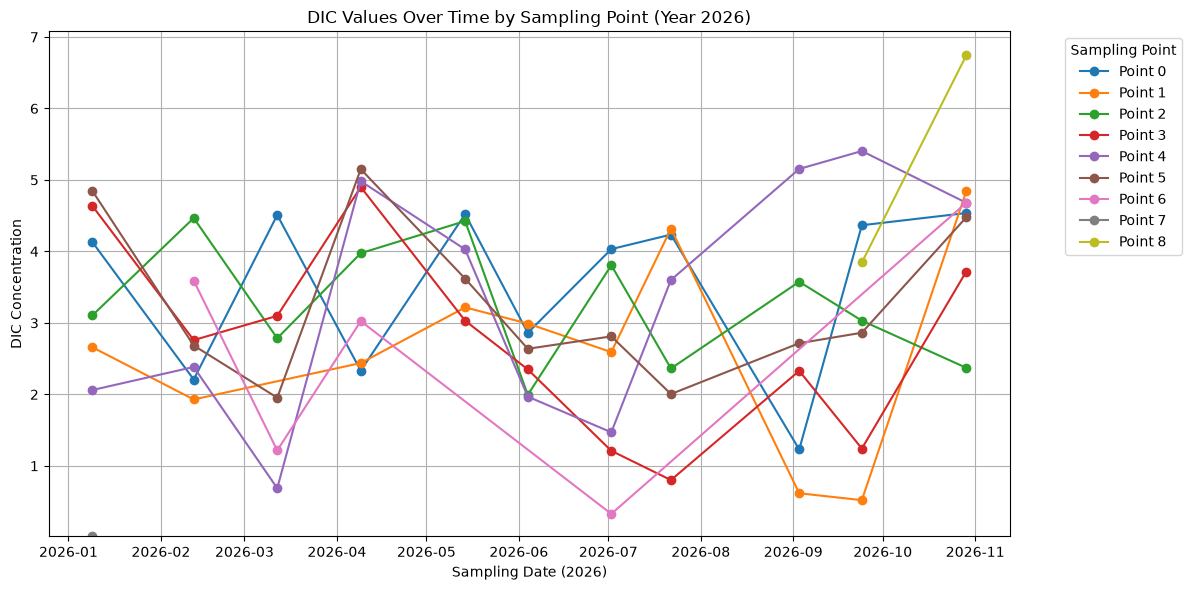

In [8]:
# 3. Filter for the year 2026, drop missing values, and sort chronologically
datos_2026 = datos[datos["sampling_date"].dt.year == 2026].dropna(subset=["sampling_date", "DIC", "sampling_point"]).sort_values("sampling_date")

# 4. Create the figure and axis
fig, ax = plt.subplots(figsize=(12, 6))

# 5. Loop through each sampling point and plot on the same graph
for point, group in datos_2026.groupby("sampling_point"):
    ax.plot(group["sampling_date"], group["DIC"], marker="o", label=point)

# 6. Set Y-axis range automatically based ONLY on 2026 values (with a 5% margin)
if not datos_2026.empty:
    ymin = datos_2026["DIC"].min()
    ymax = datos_2026["DIC"].max()
    ax.set_ylim(ymin * 0.95, ymax * 1.05)

# 7. Add labels, legend, and grid
ax.set_xlabel("Sampling Date (2026)")
ax.set_ylabel("DIC Concentration")
ax.set_title("DIC Values Over Time by Sampling Point (Year 2026)")
ax.legend(title="Sampling Point", bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(True)

plt.tight_layout()
plt.show()

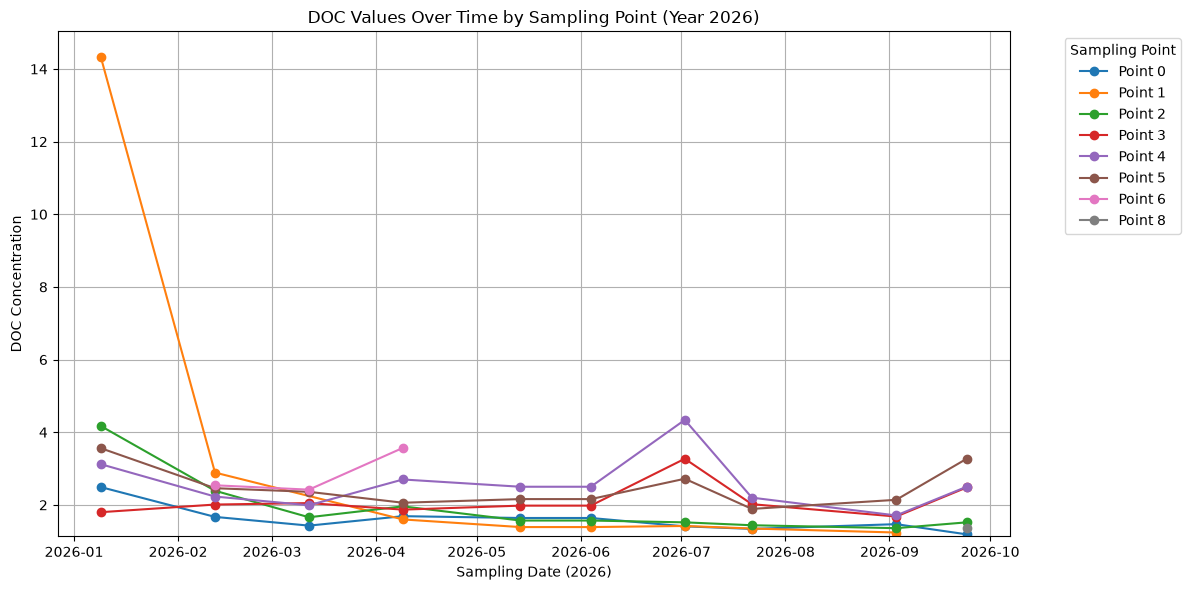

In [9]:
# 3. Filter for the year 2026, drop missing values, and sort chronologically
datos_2026 = datos[datos["sampling_date"].dt.year == 2026].dropna(subset=["sampling_date", "DOC", "sampling_point"]).sort_values("sampling_date")

# 4. Create the figure and axis
fig, ax = plt.subplots(figsize=(12, 6))

# 5. Loop through each sampling point and plot on the same graph
for point, group in datos_2026.groupby("sampling_point"):
    ax.plot(group["sampling_date"], group["DOC"], marker="o", label=point)

# 6. Set Y-axis range automatically based ONLY on 2026 values (with a 5% margin)
if not datos_2026.empty:
    ymin = datos_2026["DOC"].min()
    ymax = datos_2026["DOC"].max()
    ax.set_ylim(ymin * 0.95, ymax * 1.05)

# 7. Add labels, legend, and grid
ax.set_xlabel("Sampling Date (2026)")
ax.set_ylabel("DOC Concentration")
ax.set_title("DOC Values Over Time by Sampling Point (Year 2026)")
ax.legend(title="Sampling Point", bbox_to_anchor=(1.05, 1), loc='upper left')
ax.grid(True)

plt.tight_layout()
plt.show()

## DIC por puntos individualmente

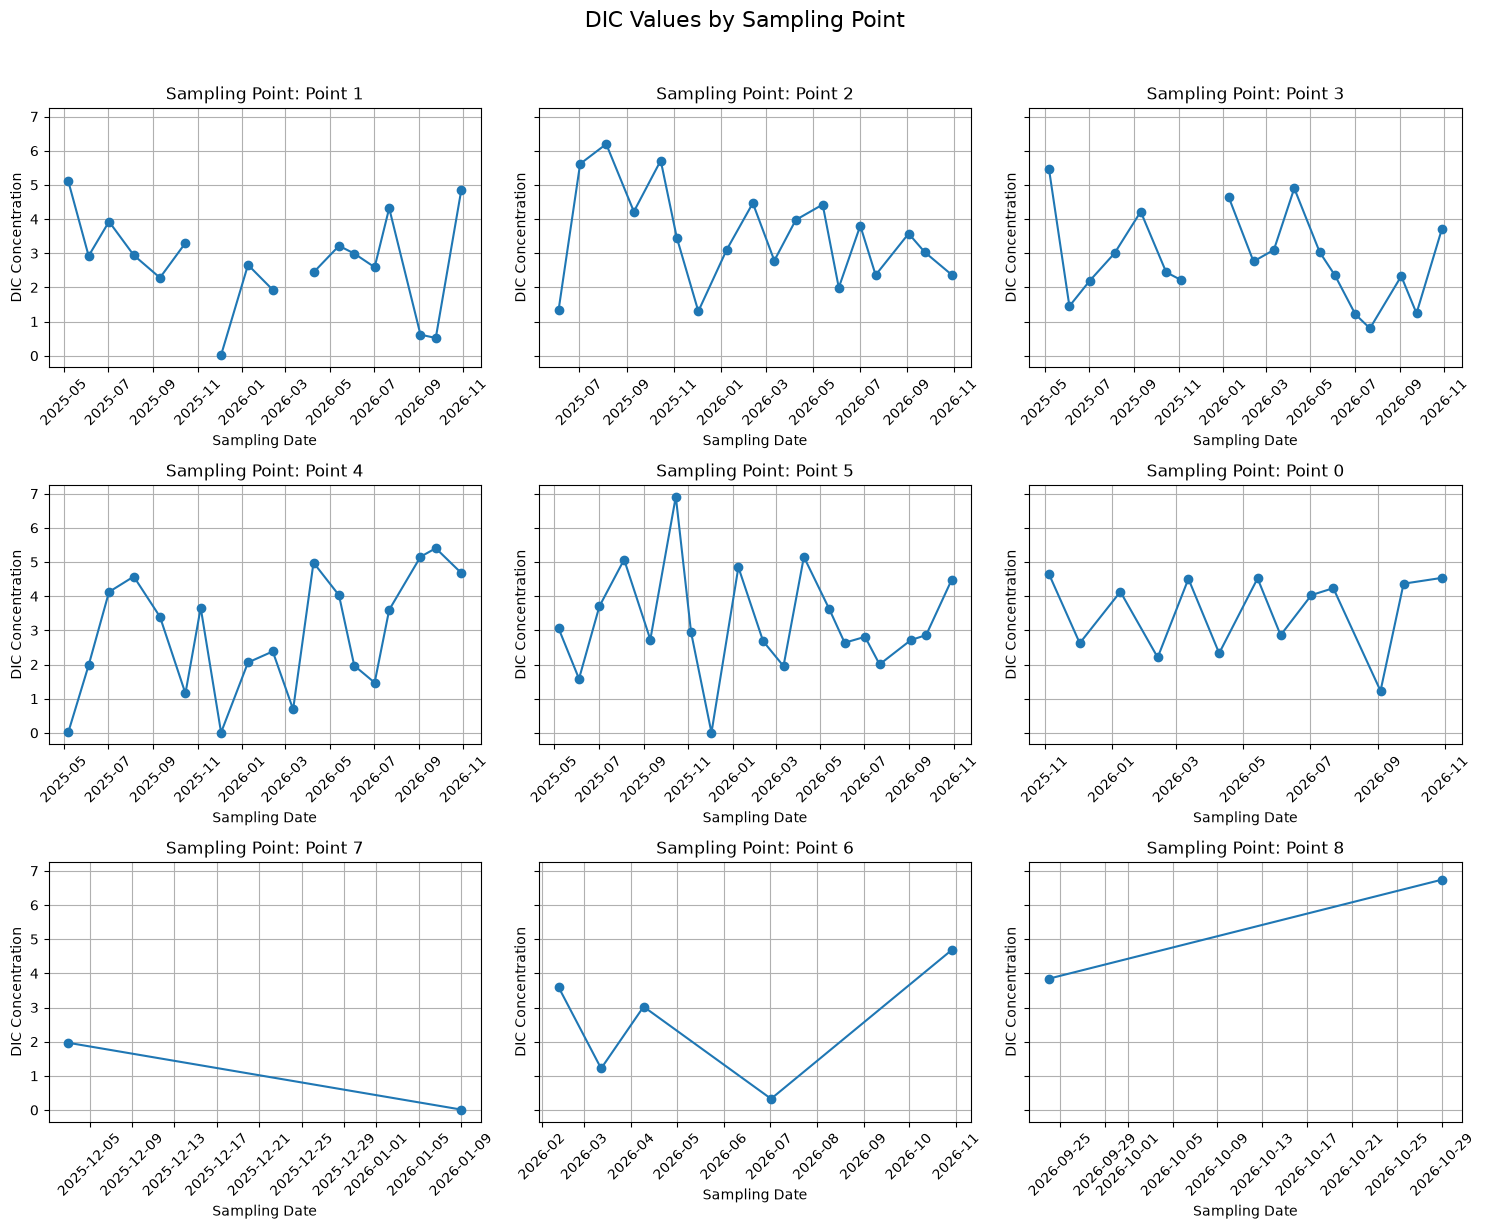

In [10]:
# 4. Get the unique sampling points and set up a grid of subplots (e.g., 3 columns)
points = datos["sampling_point"].unique()
n_cols = 3
n_rows = (len(points) + n_cols - 1) // n_cols  # Calculates rows needed automatically

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(15, 4 * n_rows), sharey=True)
axes = axes.flatten()  # Flatten so we can easily loop through 1D index

# 5. Loop through each point and plot it on its own subplot
for i, point in enumerate(points):
    ax = axes[i]
    group = datos[datos["sampling_point"] == point]
    
    ax.plot(group["sampling_date"], group["DIC"], marker="o", color="tab:blue", linestyle="-")
    
    # Customizations per panel
    ax.set_title(f"Sampling Point: {point}")
    ax.set_xlabel("Sampling Date")
    ax.set_ylabel("DIC Concentration")
    ax.grid(True)
    ax.tick_params(axis='x', rotation=45)

# 6. Remove any empty subplots if your grid has extra spaces
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# 7. Final layout adjustments
fig.suptitle("DIC Values by Sampling Point", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

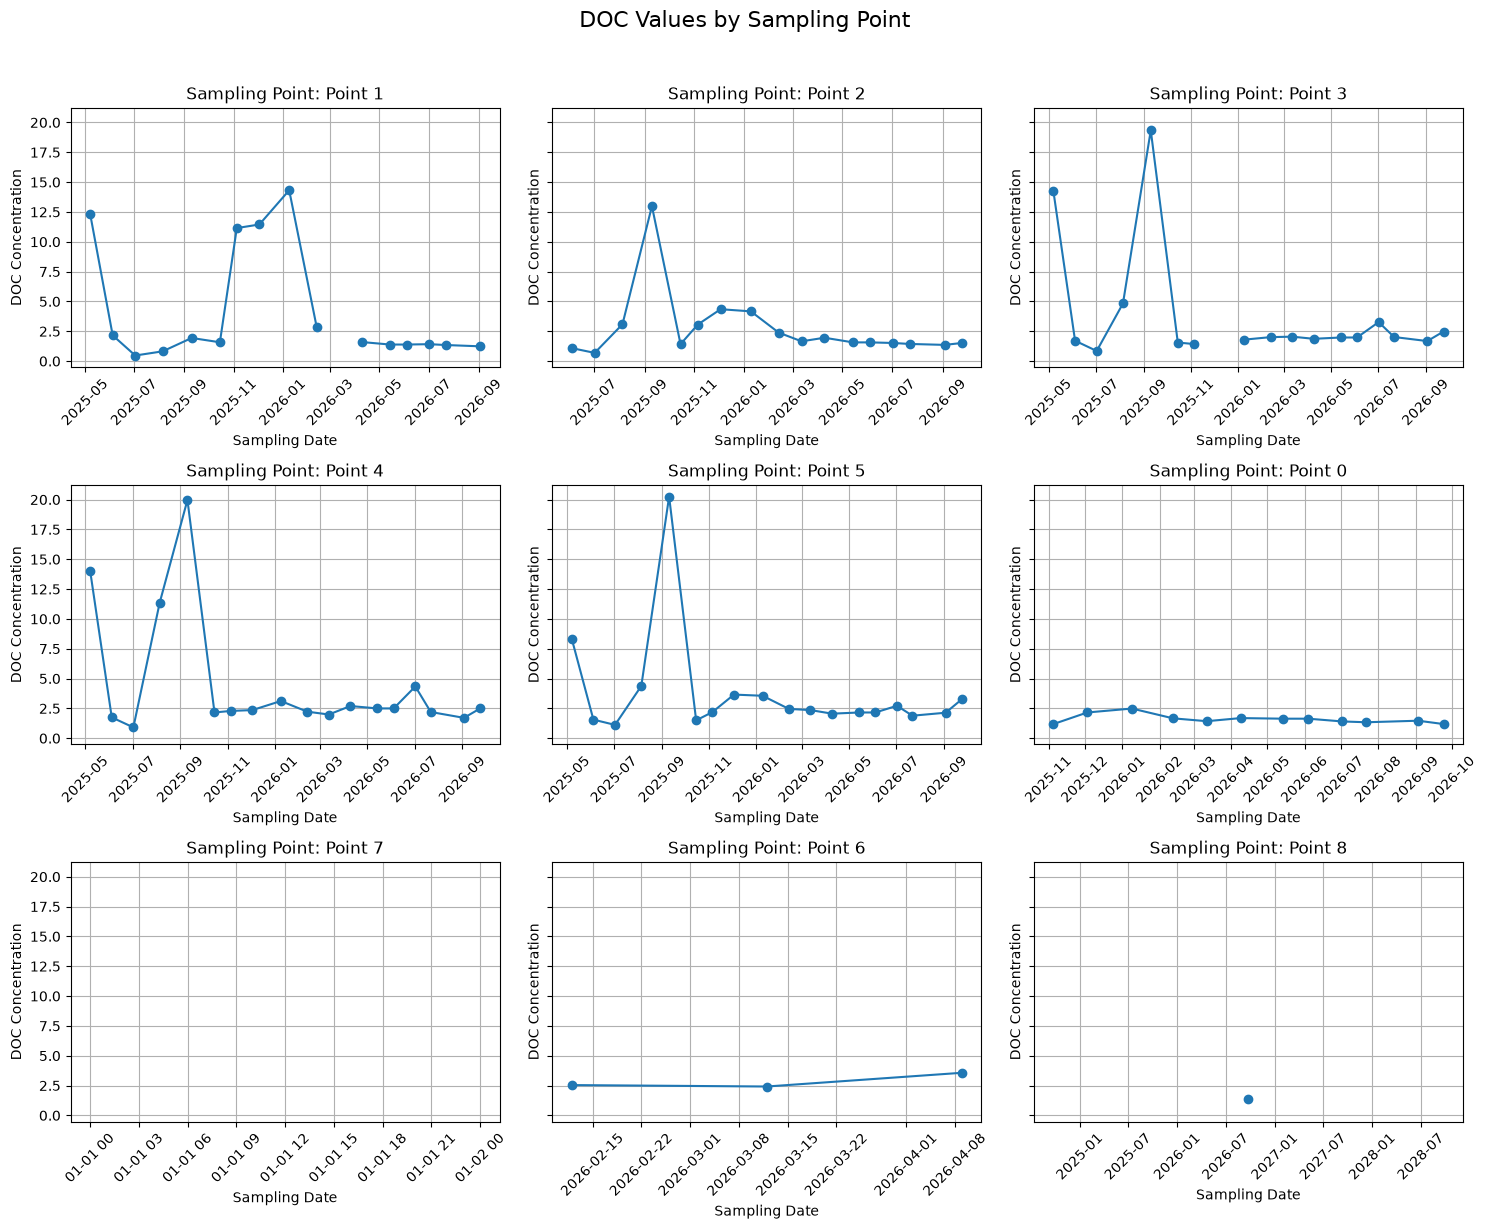

In [11]:
# 4. Get the unique sampling points and set up a grid of subplots (e.g., 3 columns)
points = datos["sampling_point"].unique()
n_cols = 3
n_rows = (len(points) + n_cols - 1) // n_cols  # Calculates rows needed automatically

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(15, 4 * n_rows), sharey=True)
axes = axes.flatten()  # Flatten so we can easily loop through 1D index

# 5. Loop through each point and plot it on its own subplot
for i, point in enumerate(points):
    ax = axes[i]
    group = datos[datos["sampling_point"] == point]
    
    ax.plot(group["sampling_date"], group["DOC"], marker="o", color="tab:blue", linestyle="-")
    
    # Customizations per panel
    ax.set_title(f"Sampling Point: {point}")
    ax.set_xlabel("Sampling Date")
    ax.set_ylabel("DOC Concentration")
    ax.grid(True)
    ax.tick_params(axis='x', rotation=45)

# 6. Remove any empty subplots if your grid has extra spaces
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# 7. Final layout adjustments
fig.suptitle("DOC Values by Sampling Point", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## Comparación de DIC y DOC

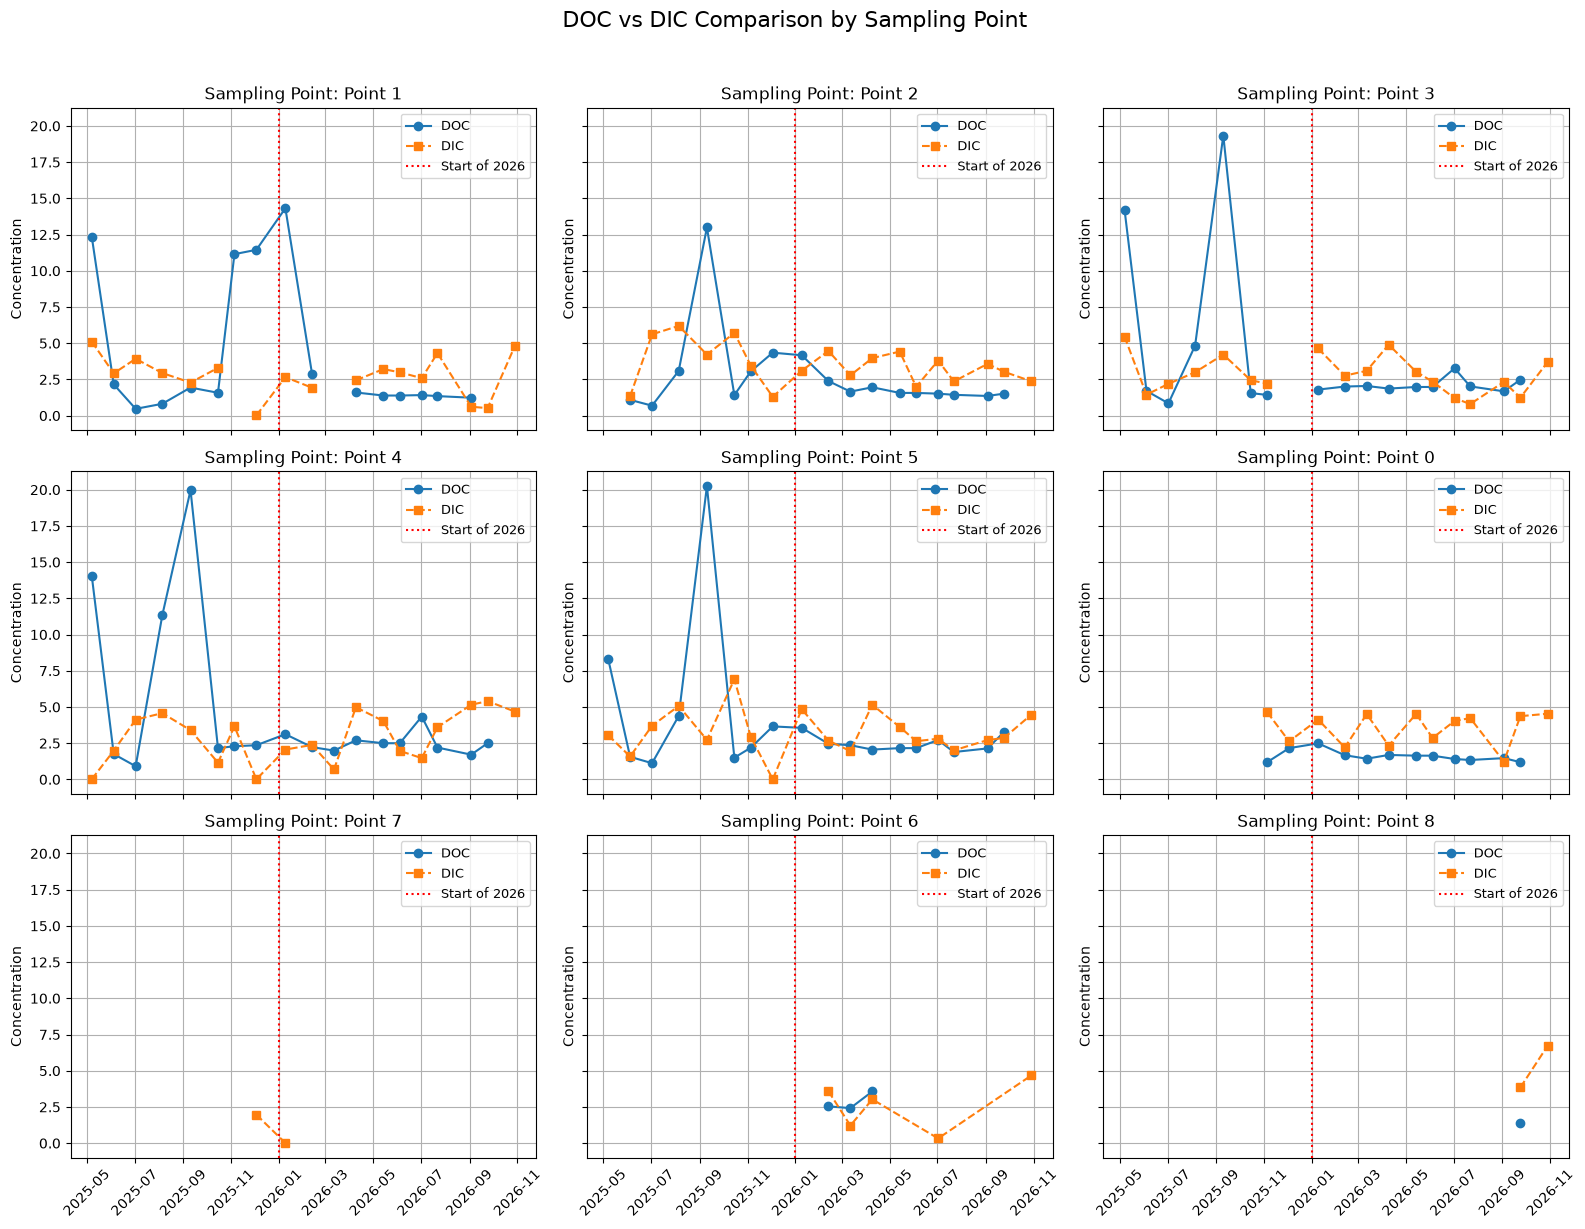

In [12]:
# 4. Get unique sampling points and set up a subplot grid (e.g., 3 columns)
points = datos["sampling_point"].dropna().unique()
n_cols = 3
n_rows = (len(points) + n_cols - 1) // n_cols

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(16, 4 * n_rows), sharex=True, sharey=True)
axes = axes.flatten()

# 5. Define the transition date for the vertical line
transition_date = pd.to_datetime('2026-01-01')

# 6. Loop through each sampling point and plot both DOC and DIC (DI)
for i, point in enumerate(points):
    ax = axes[i]
    group = datos[datos["sampling_point"] == point]
    
    # Plot DOC line
    ax.plot(group["sampling_date"], group["DOC"], marker="o", color="tab:blue", label="DOC", linestyle="-")
    
    # Plot DIC (DI) line
    ax.plot(group["sampling_date"], group["DIC"], marker="s", color="tab:orange", label="DIC", linestyle="--")

# Add vertical line for the year change
    ax.axvline(transition_date, color='red', linestyle=':', linewidth=1.5, label='Start of 2026')
    
    # Subplot formatting
    ax.set_title(f"Sampling Point: {point}")
    ax.set_ylabel("Concentration")
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(True)
    ax.tick_params(axis='x', rotation=45)

# 7. Remove any unused grid panels
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# 8. Final layout adjustments
fig.suptitle("DOC vs DIC Comparison by Sampling Point", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()